# Pembentukan Model Analisis Sentimen: TF-IDF + Linear SVM

Notebook ini **khusus untuk pembentukan dan pelatihan model** menggunakan `LinearSVC(class_weight="balanced")`. Bagian pendahuluan, tinjauan pustaka, dan penulisan laporan tidak disertakan.

**Input yang dibutuhkan:** dataset yang sudah melalui preprocessing, dengan kolom:
- `text_stopword`: teks hasil preprocessing
- `polarity`: label sentimen

Pembagian data dilakukan sebelum TF-IDF di-fit untuk menghindari *data leakage*. Bobot kelas dihitung otomatis dari data latih; tidak dilakukan oversampling.

## 1. Import library

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

RANDOM_STATE = 42

## 2. Memuat dataset

Jika variabel `app_reviews_df` sudah tersedia dari notebook preprocessing, bagian pemuatan data dapat dilewati. Jika belum, sesuaikan `DATA_PATH` dengan lokasi file dataset.

In [2]:
url='https://drive.google.com/uc?id=1gwMK2dt96YR95V4vA87vPCtQvXlUw8wo'
app_reviews_df = pd.read_csv(url)

In [3]:
# Opsi A: jika dataset sudah dimuat di notebook, biarkan baris pembacaan di bawah sebagai komentar.
# app_reviews_df = pd.read_csv("dataset_preprocessed.csv")

# Periksa bahwa dataset sudah tersedia
try:
    app_reviews_df.head()
except NameError:
    raise NameError(
        "Variabel app_reviews_df belum tersedia. Muat dataset hasil preprocessing "
        "terlebih dahulu, lalu jalankan ulang sel ini."
    )

required_columns = {"text_stopword", "polarity"}
missing_columns = required_columns - set(app_reviews_df.columns)
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {sorted(missing_columns)}")

model_df = app_reviews_df[["text_stopword", "polarity"]].copy()
model_df = model_df.dropna(subset=["text_stopword", "polarity"])
model_df["text_stopword"] = model_df["text_stopword"].astype(str).str.strip()
model_df = model_df[model_df["text_stopword"].ne("")]

print("Jumlah data siap modeling:", len(model_df))
print("\nDistribusi label:")
display(model_df["polarity"].value_counts().to_frame("jumlah"))

Jumlah data siap modeling: 14981

Distribusi label:


,jumlah
polarity,
positive,10858
negative,3402
neutral,721


## 3. Memisahkan data latih, data evaluasi dan data uji

In [4]:
X = model_df["text_stopword"]
y = model_df["polarity"]

# Split pertama: 70% train dan 30% sisa.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

# Bagi sisa 30% menjadi 15% validation dan 15% test.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Train      : {len(X_train):,} ({len(X_train)/len(model_df):.1%})")
print(f"Validation : {len(X_val):,} ({len(X_val)/len(model_df):.1%})")
print(f"Test       : {len(X_test):,} ({len(X_test)/len(model_df):.1%})")

dist = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True)
}).fillna(0)
display(dist.round(3))

Train      : 10,486 (70.0%)
Validation : 2,247 (15.0%)
Test       : 2,248 (15.0%)


,train,validation,test
polarity,,,
positive,0.725,0.725,0.725
negative,0.227,0.227,0.227
neutral,0.048,0.048,0.048


## 4. Membentuk arsitektur model

Alur model:

`Teks hasil preprocessing → TF-IDF → Linear SVM dengan class_weight='balanced' → Prediksi sentimen`

- **TF-IDF:** mengubah teks menjadi representasi fitur numerik.
- **LinearSVC:** mempelajari batas pemisah linear antarkelas.
- **Class weighting:** memberi bobot lebih besar kepada kelas yang jumlahnya lebih sedikit.
- **Loss:** LinearSVC menggunakan squared hinge loss secara default (`loss="squared_hinge"`).
- **Optimisasi:** solver internal LIBLINEAR, dengan parameter regularisasi `C`.
- **Optimizer Adam tidak digunakan**, karena model ini adalah SVM, bukan neural network.

In [5]:
from sklearn.model_selection import ParameterGrid

def build_model(params):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=params["max_features"],
            ngram_range=params["ngram_range"],
            min_df=params["min_df"],
            max_df=0.95,
            sublinear_tf=True
        )),
        ("svm", LinearSVC(
            C=params["C"],
            class_weight="balanced",
            loss="squared_hinge",
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ])

# Grid ringkas agar eksperimen masih realistis untuk UTS.
param_grid = {
    "max_features": [7000, 10000],
    "ngram_range": [(1, 1), (1, 2)],
    "min_df": [2],
    "C": [0.5, 1.0, 2.0]
}
params_list = list(ParameterGrid(param_grid))
print("Jumlah konfigurasi:", len(params_list))

Jumlah konfigurasi: 12


## 5. Melatih model

In [6]:
from sklearn.metrics import f1_score

validation_results = []
best_model = None
best_params = None
best_macro_f1 = -1.0

for i, params in enumerate(params_list, start=1):
    candidate = build_model(params)
    candidate.fit(X_train, y_train)
    val_pred = candidate.predict(X_val)

    macro_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
    accuracy = accuracy_score(y_val, val_pred)

    validation_results.append({
        **params,
        "validation_accuracy": accuracy,
        "validation_macro_f1": macro_f1
    })

    if macro_f1 > best_macro_f1:
        best_macro_f1 = macro_f1
        best_model = candidate
        best_params = params

    print(f"[{i}/{len(params_list)}] Macro-F1 val={macro_f1:.4f} | params={params}")

validation_df = pd.DataFrame(validation_results).sort_values(
    "validation_macro_f1", ascending=False
).reset_index(drop=True)

print("\nHyperparameter terbaik berdasarkan validation Macro-F1:")
print(best_params)
print(f"Validation Macro-F1: {best_macro_f1:.4f}")
display(validation_df.round(4))

[1/12] Macro-F1 val=0.6228 | params={'C': 0.5, 'max_features': 7000, 'min_df': 2, 'ngram_range': (1, 1)}
[2/12] Macro-F1 val=0.6114 | params={'C': 0.5, 'max_features': 7000, 'min_df': 2, 'ngram_range': (1, 2)}
[3/12] Macro-F1 val=0.6228 | params={'C': 0.5, 'max_features': 10000, 'min_df': 2, 'ngram_range': (1, 1)}
[4/12] Macro-F1 val=0.6114 | params={'C': 0.5, 'max_features': 10000, 'min_df': 2, 'ngram_range': (1, 2)}
[5/12] Macro-F1 val=0.6185 | params={'C': 1.0, 'max_features': 7000, 'min_df': 2, 'ngram_range': (1, 1)}
[6/12] Macro-F1 val=0.5998 | params={'C': 1.0, 'max_features': 7000, 'min_df': 2, 'ngram_range': (1, 2)}
[7/12] Macro-F1 val=0.6185 | params={'C': 1.0, 'max_features': 10000, 'min_df': 2, 'ngram_range': (1, 1)}
[8/12] Macro-F1 val=0.5998 | params={'C': 1.0, 'max_features': 10000, 'min_df': 2, 'ngram_range': (1, 2)}
[9/12] Macro-F1 val=0.6156 | params={'C': 2.0, 'max_features': 7000, 'min_df': 2, 'ngram_range': (1, 1)}
[10/12] Macro-F1 val=0.5939 | params={'C': 2.0, 'ma

,C,max_features,min_df,ngram_range,validation_accuracy,validation_macro_f1
0,0.5,7000,2,"(1, 1)",0.8500,0.6228
1,0.5,10000,2,"(1, 1)",0.8500,0.6228
2,1.0,10000,2,"(1, 1)",0.8451,0.6185
3,1.0,7000,2,"(1, 1)",0.8451,0.6185
4,2.0,10000,2,"(1, 1)",0.8389,0.6156
5,2.0,7000,2,"(1, 1)",0.8389,0.6156
6,0.5,10000,2,"(1, 2)",0.8527,0.6114
7,0.5,7000,2,"(1, 2)",0.8527,0.6114
8,1.0,10000,2,"(1, 2)",0.8478,0.5998
9,1.0,7000,2,"(1, 2)",0.8478,0.5998


## 6. Menghasilkan prediksi

In [7]:
y_pred = best_model.predict(X_test)

print("Contoh hasil prediksi pada Data Uji (Test Set):")
prediksi_df = pd.DataFrame({
    "teks": X_test.reset_index(drop=True),
    "label_aktual": y_test.reset_index(drop=True),
    "label_prediksi": y_pred
})
display(prediksi_df.head(10))

Contoh hasil prediksi pada Data Uji (Test Set):


,teks,label_aktual,label_prediksi
0,good job,positive,positive
1,ribet banget masalahharus telepon kena pulsato...,negative,negative
2,tidak masuk tolong mohon bantuan,negative,neutral
3,bagus,positive,positive
4,memuaskan,positive,positive
5,bagus,positive,positive
6,tau wondr pakai,neutral,positive
7,aman,positive,positive
8,nasabah bnidownload aplikasi recomended banget...,positive,positive
9,tingkatkan vitur pelayanan masiarakat,neutral,positive


## 7. Evaluasi dasar model

In [8]:
test_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_pred)
p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
    y_test, test_pred, average="macro", zero_division=0
)
p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_test, test_pred, average="weighted", zero_division=0
)

test_metrics = pd.DataFrame([{
    "Accuracy": test_accuracy,
    "Macro Precision": p_macro,
    "Macro Recall": r_macro,
    "Macro F1": f1_macro,
    "Weighted Precision": p_weighted,
    "Weighted Recall": r_weighted,
    "Weighted F1": f1_weighted
}])
display(test_metrics.round(4))

print(classification_report(y_test, test_pred, zero_division=0))

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
0,0.8399,0.5879,0.6098,0.5972,0.8546,0.8399,0.8458


              precision    recall  f1-score   support

    negative       0.70      0.80      0.75       511
     neutral       0.11      0.13      0.12       108
    positive       0.95      0.90      0.93      1629

    accuracy                           0.84      2248
   macro avg       0.59      0.61      0.60      2248
weighted avg       0.85      0.84      0.85      2248



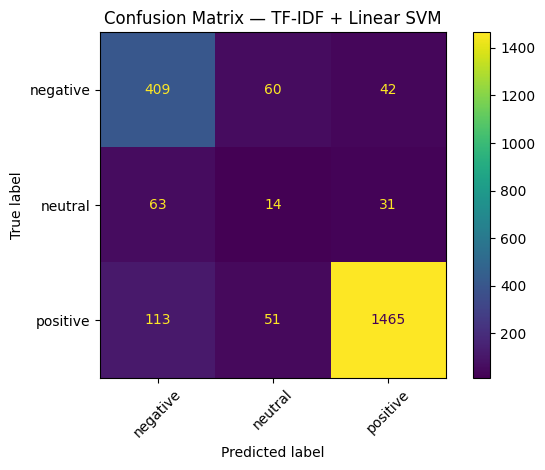

In [9]:
labels = list(best_model.named_steps["svm"].classes_)
cm = confusion_matrix(y_test, test_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(values_format="d", xticks_rotation=45)
plt.title("Confusion Matrix — TF-IDF + Linear SVM")
plt.tight_layout()
plt.show()

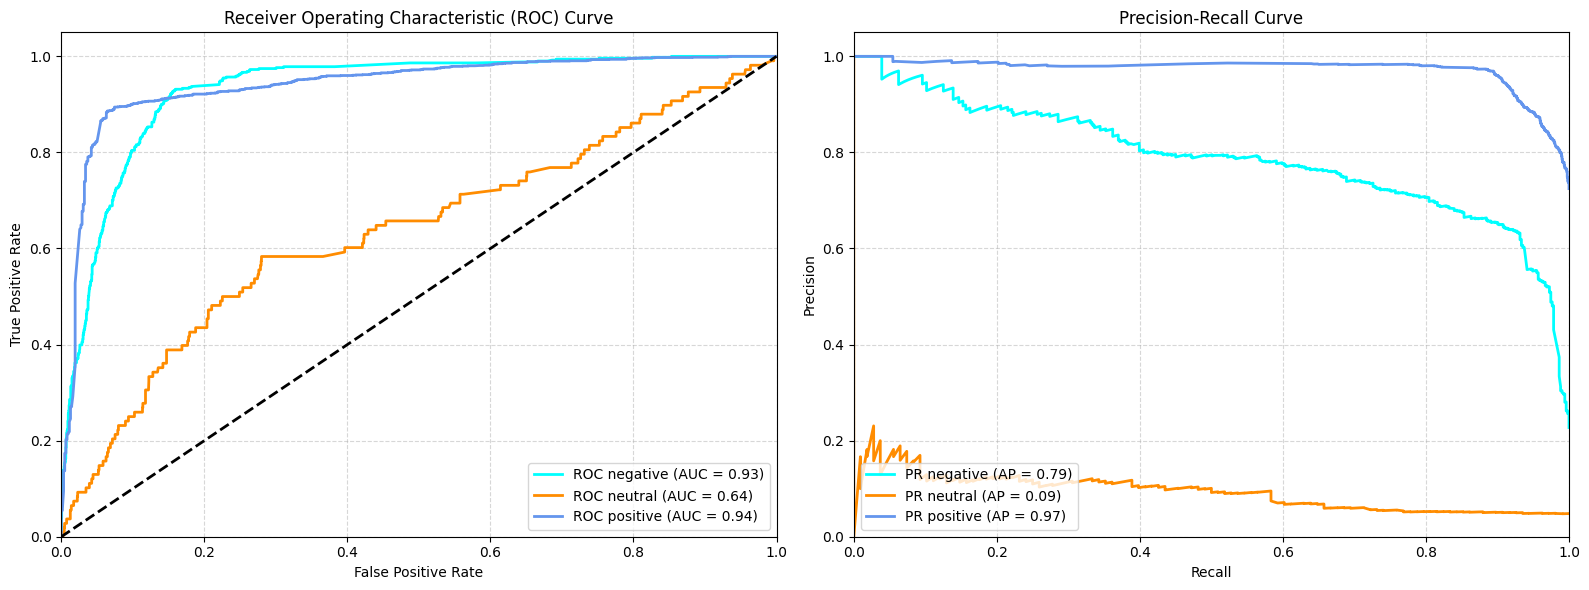

In [10]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# Binarize label target untuk evaluasi multi-kelas
classes = list(best_model.named_steps["svm"].classes_)
n_classes = len(classes)
y_test_bin = label_binarize(y_test, classes=classes)

# LinearSVC menggunakan decision_function untuk mengukur tingkat keyakinan (confidence score)
y_score = best_model.decision_function(X_test)

# Plot ROC & Precision-Recall Curves
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

colors = ['aqua', 'darkorange', 'cornflowerblue']

# 1. ROC Curve
for i, color in enumerate(colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    ax[0].plot(
        fpr, tpr, color=color, lw=2,
        label=f'ROC {classes[i]} (AUC = {roc_auc:.2f})'
    )
ax[0].plot([0, 1], [0, 1], 'k--', lw=2)
ax[0].set_xlim([0.0, 1.0])
ax[0].set_ylim([0.0, 1.05])
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].set_title('Receiver Operating Characteristic (ROC) Curve')
ax[0].legend(loc="lower right")
ax[0].grid(True, linestyle='--', alpha=0.5)

# 2. Precision-Recall Curve
for i, color in enumerate(colors):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    average_precision = average_precision_score(y_test_bin[:, i], y_score[:, i])
    ax[1].plot(
        recall, precision, color=color, lw=2,
        label=f'PR {classes[i]} (AP = {average_precision:.2f})'
    )
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-Recall Curve')
ax[1].legend(loc="lower left")
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [11]:
error_df = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": test_pred
})
error_df = error_df[error_df["actual"] != error_df["predicted"]]
print("Jumlah prediksi salah:", len(error_df))
display(error_df.head(20))

Jumlah prediksi salah: 360


,text,actual,predicted
2,tidak masuk tolong mohon bantuan,negative,neutral
6,tau wondr pakai,neutral,positive
9,tingkatkan vitur pelayanan masiarakat,neutral,positive
12,min adain fitur bni simple pip top uptransfer ...,neutral,positive
17,error mohon kebijakan bni mengatasi,negative,positive
30,kasih menu setor tunai dongmasa pakai mbanking...,neutral,negative
34,wonder tidak kebuka,positive,negative
36,macet loading masuk kedalam menu tidak banking...,negative,neutral
39,mw buka wondr bnitp muncul wondr akses menyele...,neutral,positive
49,update aplikasinya tidak dibuka perangkat pons...,negative,neutral


## 8. Menyimpan model terlatih (opsional)

Jalankan sel berikut jika model akan digunakan kembali tanpa melatih ulang. File disimpan di direktori kerja notebook.

In [12]:
import joblib

# Menyimpan model terbaik hasil hyperparameter tuning
joblib.dump(best_model, "tfidf_linear_svm_balanced.joblib")
print("Model disimpan sebagai tfidf_linear_svm_balanced.joblib")

Model disimpan sebagai tfidf_linear_svm_balanced.joblib


## Catatan

- Hasil evaluasi baru valid setelah seluruh sel berhasil dijalankan menggunakan dataset yang sebenarnya.
- Pastikan label pada kolom `polarity` sesuai dengan definisi kelas sentimen pada dataset.
- `class_weight="balanced"` tidak mengubah distribusi data; metode ini mengatur bobot penalti kesalahan selama pelatihan.
- Parameter TF-IDF dan `C` di atas adalah konfigurasi awal yang wajar, bukan klaim bahwa parameter tersebut sudah optimal. Untuk memilih hyperparameter terbaik secara empiris, lakukan cross-validation hanya pada data latih.